In [ ]:
# If needed, install once in a Jupyter cell:
# %pip install pandas numpy matplotlib scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score,
confusion_matrix, classification_report,
ConfusionMatrixDisplay
)

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]
df = pd.read_csv(url, header=None, names=columns)
print(df.head())
print("Dataset shape:", df.shape)
print(df.info())

   Variance  Skewness  Curtosis  Entropy  Class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
Dataset shape: (1372, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
None


In [ ]:
print(df.head(10))
print(df.shape)
print(df.isnull().sum())
print(df.describe())
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

   Variance  Skewness  Curtosis  Entropy  Class
0   3.62160    8.6661  -2.80730 -0.44699      0
1   4.54590    8.1674  -2.45860 -1.46210      0
2   3.86600   -2.6383   1.92420  0.10645      0
3   3.45660    9.5228  -4.01120 -3.59440      0
4   0.32924   -4.4552   4.57180 -0.98880      0
5   4.36840    9.6718  -3.96060 -3.16250      0
6   3.59120    3.0129   0.72888  0.56421      0
7   2.09220   -6.8100   8.46360 -0.60216      0
8   3.20320    5.7588  -0.75345 -0.61251      0
9   1.53560    9.1772  -2.27180 -0.73535      0
(1372, 5)
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64
          Variance     Skewness     Curtosis      Entropy        Class
count  1372.000000  1372.000000  1372.000000  1372.000000  1372.000000
mean      0.433735     1.922353     1.397627    -1.191657     0.444606
std       2.842763     5.869047     4.310030     2.101013     0.497103
min      -7.042100   -13.773100    -5.286100    -8.548200     0.000000
25%      -1.773000    -1

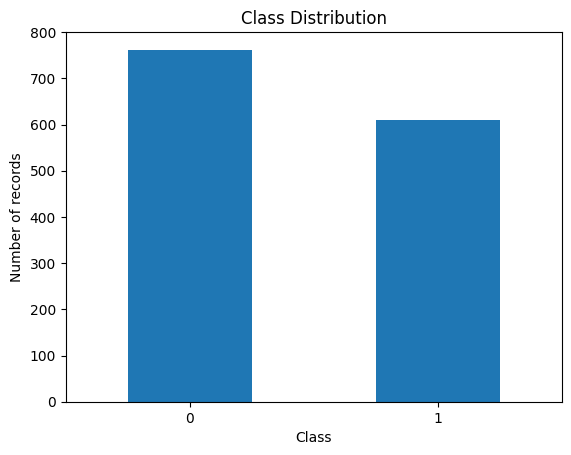

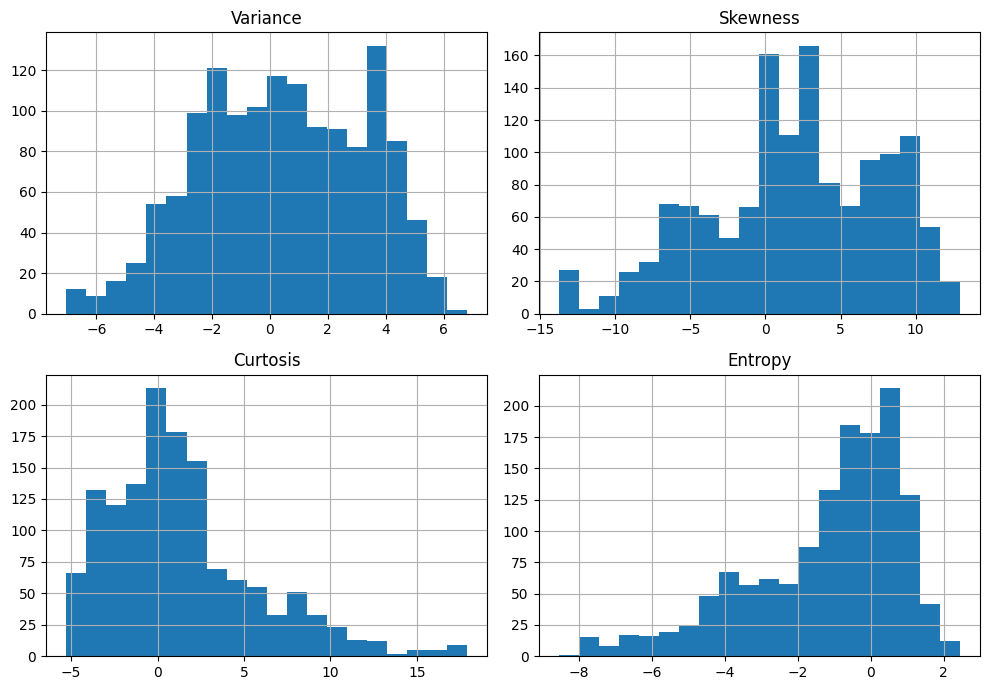

In [ ]:
df["Class"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Class")
plt.ylabel("Number of records")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()
df[["Variance", "Skewness", "Curtosis", "Entropy"]].hist(
figsize=(10, 7), bins=20
)
plt.tight_layout()
plt.show()

In [ ]:
X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]
y = df["Class"]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (1372, 4)
Target shape: (1372,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.20,
random_state=42,
stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1097
Testing records: 275


In [ ]:
model = make_pipeline(
StandardScaler(),
LogisticRegression(max_iter=1000)
)
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


In [ ]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
"Actual Class": y_test.values,
"Predicted Class": y_pred
})
print(results.head(15))

    Actual Class  Predicted Class
0              0                0
1              1                1
2              0                0
3              1                1
4              1                1
5              1                1
6              0                0
7              0                0
8              0                0
9              1                1
10             0                0
11             1                1
12             0                0
13             0                0
14             0                0


In [ ]:
y_probability = model.predict_proba(X_test)
probability_results = pd.DataFrame(
y_probability,
columns=["Probability of Class 0", "Probability of Class 1"]
)
print(probability_results.head())

   Probability of Class 0  Probability of Class 1
0                0.999576                0.000424
1                0.033572                0.966428
2                0.755631                0.244369
3                0.035568                0.964432
4                0.006959                0.993041


In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.9709090909090909
Precision: 0.9384615384615385
Recall : 1.0
F1-score : 0.9682539682539683

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



[[145   8]
 [  0 122]]


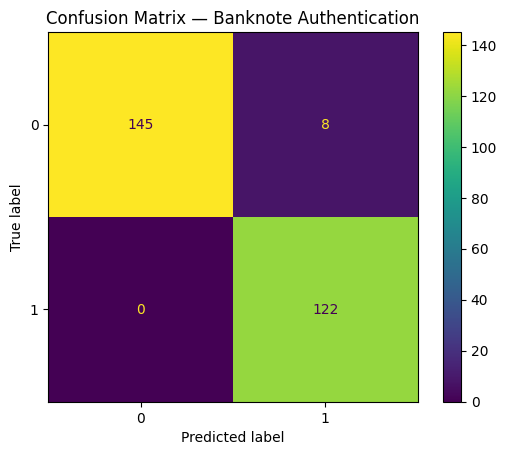

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(cm)
ConfusionMatrixDisplay(
confusion_matrix=cm,
display_labels=[0, 1]
).plot()
plt.title("Confusion Matrix — Banknote Authentication")
plt.show()

In [ ]:
class_1_probability = model.predict_proba(X_test)[:, 1]
for threshold in [0.30, 0.50, 0.70]:
  threshold_pred = (class_1_probability >= threshold).astype(int)
  print("\nThreshold:", threshold)
  print("Accuracy :", accuracy_score(y_test, threshold_pred))
  print("Precision:", precision_score(y_test, threshold_pred, zero_division=0))
  print("Recall :", recall_score(y_test, threshold_pred, zero_division=0))
  print("F1-score :", f1_score(y_test, threshold_pred, zero_division=0))
  print("Confusion matrix:")
  print(confusion_matrix(y_test, threshold_pred, labels=[0, 1]))


Threshold: 0.3
Accuracy : 0.9709090909090909
Precision: 0.9384615384615385
Recall : 1.0
F1-score : 0.9682539682539683
Confusion matrix:
[[145   8]
 [  0 122]]

Threshold: 0.5
Accuracy : 0.9709090909090909
Precision: 0.9384615384615385
Recall : 1.0
F1-score : 0.9682539682539683
Confusion matrix:
[[145   8]
 [  0 122]]

Threshold: 0.7
Accuracy : 0.9963636363636363
Precision: 0.991869918699187
Recall : 1.0
F1-score : 0.9959183673469387
Confusion matrix:
[[152   1]
 [  0 122]]


5-Fold CV Accuracy: 0.9811 ± 0.0063
Decision Tree Test Accuracy: 0.9927


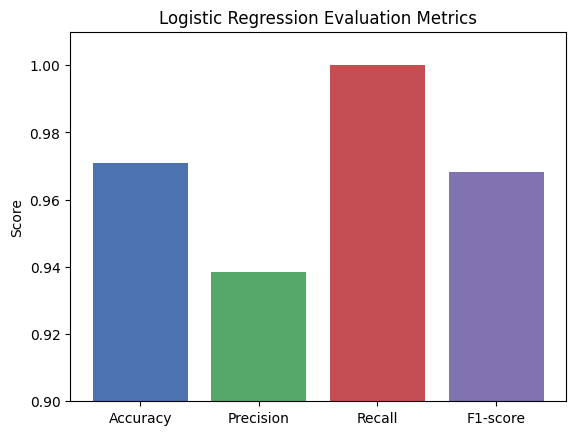

C=0.01   | Test Accuracy: 0.9382
C=0.1    | Test Accuracy: 0.9709
C=1.0    | Test Accuracy: 0.9709
C=10.0   | Test Accuracy: 0.9855
C=100.0  | Test Accuracy: 0.9855
{'Predicted Class': 'Genuine (0)', 'Prob Genuine (0)': np.float64(0.9996), 'Prob Forged (1)': np.float64(0.0004)}


In [28]:
# section 9 etended part

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

# 1. 5-fold StratifiedKFold cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
print(f"5-Fold CV Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# 2. Compare Logistic Regression with a Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print(f"Decision Tree Test Accuracy: {accuracy_score(y_test, dt_pred):.4f}")

# 3. Bar chart comparing Logistic Regression metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred)
}
plt.bar(metrics.keys(), metrics.values(), color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
plt.ylim(0.9, 1.01)
plt.ylabel("Score")
plt.title("Logistic Regression Evaluation Metrics")
plt.show()

# 4. Effect of changing regularisation parameter C
for c_val in [0.01, 0.1, 1.0, 10.0, 100.0]:
    temp_model = make_pipeline(StandardScaler(), LogisticRegression(C=c_val, max_iter=1000))
    temp_model.fit(X_train, y_train)
    print(f"C={c_val:<6} | Test Accuracy: {temp_model.score(X_test, y_test):.4f}")

# 5. Custom prediction function
def predict_banknote(variance, skewness, curtosis, entropy):
    sample = pd.DataFrame([[variance, skewness, curtosis, entropy]],
                          columns=["Variance", "Skewness", "Curtosis", "Entropy"])
    pred_class = model.predict(sample)[0]
    probs = model.predict_proba(sample)[0]
    label_name = "Forged (1)" if pred_class == 1 else "Genuine (0)"
    return {
        "Predicted Class": label_name,
        "Prob Genuine (0)": round(probs[0], 4),
        "Prob Forged (1)": round(probs[1], 4)
    }

print(predict_banknote(3.6216, 8.6661, -2.8073, -0.44699))
